In [3]:
import os
import pandas as pd
import numpy as np
import plotnine

In [4]:
scaling_relationships = pd.read_csv("../data/scaling_relationships_bounds.csv")

In [5]:
scaling_relationships

,Unnamed: 0,taxon,diameter,min_diameter,max_diameter,pft,parameter_a_gr,parameter_a_gr_denom,parameter_b_gr,parameter_a_no3,...,parameter_b_no2,parameter_a_nh4,parameter_b_nh4,parameter_a_p,parameter_b_p,darwin_from_class,number_group,max_growth_rate,half_sat_n,half_sat_p
0,0,Mamiellales,1.5,0.8,6.5,PicoEuk,0.000013,86400.0,0.28,0.17,...,0.27,0.085,0.27,0.026,0.27,PicoEuk,3,1.301610,0.495624,0.030321
1,1,Leptocylindrales,15.0,5.0,16.0,Diatom,0.000029,86400.0,-0.10,0.17,...,0.27,0.085,0.27,0.026,0.27,Diatom,7,1.182059,3.200018,0.195766
2,2,Cryptomonadales,15.0,6.0,50.0,PicoEuk,0.000013,86400.0,0.28,0.17,...,0.27,0.085,0.27,0.026,0.27,PicoEuk,3,9.004944,3.200018,0.195766
3,3,Cymatosirales,5.0,1.0,20.0,Diatom,0.000029,86400.0,-0.10,0.17,...,0.27,0.085,0.27,0.026,0.27,Diatom,7,1.643522,1.314269,0.080402
4,4,Prymnesiales,5.0,4.0,18.0,PicoEuk,0.000013,86400.0,0.28,0.17,...,0.27,0.085,0.27,0.026,0.27,PicoEuk,3,3.578484,1.314269,0.080402
5,5,Suessiales,10.0,8.0,35.0,Dino,0.000015,86400.0,-0.10,0.17,...,0.27,0.085,0.27,0.026,0.27,Dino,8,0.714503,2.304191,0.140962
6,6,Hemiaulales,50.0,10.0,150.0,Diatom,0.000029,86400.0,-0.10,0.17,...,0.27,0.085,0.27,0.026,0.27,Diatom,7,0.823712,8.485633,0.519121
7,7,Chaetocerotophycidae,25.0,2.0,50.0,Diatom,0.000029,86400.0,-0.10,0.17,...,0.27,0.085,0.27,0.026,0.27,Diatom,7,1.014109,4.840051,0.296097
8,8,Rhizosoleniales,100.0,5.0,100.0,Diatom,0.000029,86400.0,-0.10,0.17,...,0.27,0.085,0.27,0.026,0.27,Diatom,7,0.669062,14.877109,0.910129
9,9,Gymnodiniales,10.0,5.0,200.0,Dino,0.000015,86400.0,-0.10,0.17,...,0.27,0.085,0.27,0.026,0.27,Dino,8,0.714503,2.304191,0.140962


In [6]:
scaling_relationships.parameter_a_p = scaling_relationships.parameter_a_p.astype(float)

In [7]:
growth_rates=[]
half_sats_n=[]
half_sats_p=[]
half_sats_n_min=[]
half_sats_p_min=[]
half_sats_n_max=[]
half_sats_p_max=[]
for taxon,rownum in zip(scaling_relationships.taxon,scaling_relationships.index):
    ## calculate maximum growth rates
    V=1/6*np.pi*scaling_relationships.diameter[rownum]**3
    V_min=1/6*np.pi*scaling_relationships.min_diameter[rownum]**3
    V_max=1/6*np.pi*scaling_relationships.max_diameter[rownum]**3
    
    a=scaling_relationships.parameter_a_gr[rownum]*\
      scaling_relationships.parameter_a_gr_denom[rownum]
    b=scaling_relationships.parameter_b_gr[rownum]
    mu = a*V**b
    
    growth_rates.append(mu)
    
    ## calculate half sat for N
    half_sat_no3 = scaling_relationships.parameter_a_no3[rownum]*V**\
        scaling_relationships.parameter_b_no3[rownum]
    half_sat_no2 = scaling_relationships.parameter_a_no2[rownum]*V**\
        scaling_relationships.parameter_b_no2[rownum]
    half_sat_nh4 = scaling_relationships.parameter_a_nh4[rownum]*V**\
        scaling_relationships.parameter_b_nh4[rownum]
    half_sat_n=half_sat_no3+half_sat_no2+half_sat_nh4
    half_sats_n.append(half_sat_n)
    
    ## calculate min half sat for N
    half_sat_no3 = scaling_relationships.parameter_a_no3[rownum]*V_min**\
        scaling_relationships.parameter_b_no3[rownum]
    half_sat_no2 = scaling_relationships.parameter_a_no2[rownum]*V_min**\
        scaling_relationships.parameter_b_no2[rownum]
    half_sat_nh4 = scaling_relationships.parameter_a_nh4[rownum]*V_min**\
        scaling_relationships.parameter_b_nh4[rownum]
    half_sat_n=half_sat_no3+half_sat_no2+half_sat_nh4
    half_sats_n_min.append(half_sat_n)
    
    ## calculate max half sat for N
    half_sat_no3 = scaling_relationships.parameter_a_no3[rownum]*V_max**\
        scaling_relationships.parameter_b_no3[rownum]
    half_sat_no2 = scaling_relationships.parameter_a_no2[rownum]*V_max**\
        scaling_relationships.parameter_b_no2[rownum]
    half_sat_nh4 = scaling_relationships.parameter_a_nh4[rownum]*V_max**\
        scaling_relationships.parameter_b_nh4[rownum]
    half_sat_n=half_sat_no3+half_sat_no2+half_sat_nh4
    half_sats_n_max.append(half_sat_n)
    
    ## calculate half sat for P
    half_sats_p.append(scaling_relationships.parameter_a_p[rownum]*V**\
        scaling_relationships.parameter_b_p[rownum])
    
    ## calculate min half sat for P
    half_sats_p_min.append(scaling_relationships.parameter_a_p[rownum]*V_min**\
        scaling_relationships.parameter_b_p[rownum])
    
    ## calculate max half sat for P
    half_sats_p_max.append(scaling_relationships.parameter_a_p[rownum]*V_max**\
        scaling_relationships.parameter_b_p[rownum])
    
scaling_relationships["max_growth_rate"]=growth_rates
scaling_relationships["half_sat_n"]=half_sats_n
scaling_relationships["half_sat_p"]=half_sats_p


scaling_relationships["half_sat_n_min"]=half_sats_n_min
scaling_relationships["half_sat_p_min"]=half_sats_p_min
scaling_relationships["half_sat_n_max"]=half_sats_n_max
scaling_relationships["half_sat_p_max"]=half_sats_p_max

In [8]:
scaling_relationships = scaling_relationships.loc[[curr in ['Mamiellales','Leptocylindrales',
                                                            'Cryptomonadales',
                             'Prymnesiales','Suessiales','Hemiaulales',
                             'Chaetocerotophycidae','Rhizosoleniales','Gymnodiniales',
                             'Coscinodiscales','Gonyaulacales','Bacillariales',
                             'Thalassiosirales','Phaeocystales','Isochrysidales',
                             'Melosirales','Lithodesmiales','Pyramimonadales_X',
                             'Parmales','Prorocentrales'] for curr in\
                                                   scaling_relationships.taxon],:]
scaling_relationships.to_csv("../data/scaling_relationships_range_calc.csv")

In [9]:
scaling_relationships

,Unnamed: 0,taxon,diameter,min_diameter,max_diameter,pft,parameter_a_gr,parameter_a_gr_denom,parameter_b_gr,parameter_a_no3,...,parameter_b_p,darwin_from_class,number_group,max_growth_rate,half_sat_n,half_sat_p,half_sat_n_min,half_sat_p_min,half_sat_n_max,half_sat_p_max
0,0,Mamiellales,1.5,0.8,6.5,PicoEuk,0.000013,86400.0,0.28,0.17,...,0.27,PicoEuk,3,1.301610,0.495624,0.030321,0.297866,0.018222,1.625468,0.099440
1,1,Leptocylindrales,15.0,5.0,16.0,Diatom,0.000029,86400.0,-0.10,0.17,...,0.27,Diatom,7,1.182059,3.200018,0.195766,1.314269,0.080402,3.371753,0.206272
2,2,Cryptomonadales,15.0,6.0,50.0,PicoEuk,0.000013,86400.0,0.28,0.17,...,0.27,PicoEuk,3,9.004944,3.200018,0.195766,1.523425,0.093198,8.485633,0.519121
4,4,Prymnesiales,5.0,4.0,18.0,PicoEuk,0.000013,86400.0,0.28,0.17,...,0.27,PicoEuk,3,3.578484,1.314269,0.080402,1.096951,0.067108,3.709277,0.226920
5,5,Suessiales,10.0,8.0,35.0,Dino,0.000015,86400.0,-0.10,0.17,...,0.27,Dino,8,0.714503,2.304191,0.140962,1.923187,0.117654,6.356436,0.388864
6,6,Hemiaulales,50.0,10.0,150.0,Diatom,0.000029,86400.0,-0.10,0.17,...,0.27,Diatom,7,0.823712,8.485633,0.519121,2.304191,0.140962,20.661054,1.263970
7,7,Chaetocerotophycidae,25.0,2.0,50.0,Diatom,0.000029,86400.0,-0.10,0.17,...,0.27,Diatom,7,1.014109,4.840051,0.296097,0.625681,0.038277,8.485633,0.519121
8,8,Rhizosoleniales,100.0,5.0,100.0,Diatom,0.000029,86400.0,-0.10,0.17,...,0.27,Diatom,7,0.669062,14.877109,0.910129,1.314269,0.080402,14.877109,0.910129
9,9,Gymnodiniales,10.0,5.0,200.0,Dino,0.000015,86400.0,-0.10,0.17,...,0.27,Dino,8,0.714503,2.304191,0.140962,1.314269,0.080402,26.082719,1.595649
10,10,Coscinodiscales,150.0,30.0,500.0,Diatom,0.000029,86400.0,-0.10,0.17,...,0.27,Diatom,7,0.592433,20.661054,1.263970,5.610309,0.343219,54.787850,3.351727


In [11]:
half_sats_p = pd.read_csv("../../2026_08_29_complete_workflow/output_estimation_logN_linP_20260918/half_sats/phosphorus_half_sats.csv")
half_sats_p = pd.read_csv("../output/for_paper_stats_frame_p.csv")
half_sats_p = pd.read_csv("../../2026_08_29_complete_workflow/output_estimation_logN_linP_20261009/half_sats/phosphorus_half_sats.csv")

half_sats_p = half_sats_p.loc[half_sats_p.exponential_p_val < 0.11,:]
half_sats_p = half_sats_p.loc[(half_sats_p.exponential_slope <= 0)|(half_sats_p.Taxon=="Coscinodiscales"),:]
half_sats_p["metaT_p_half_sat"]=half_sats_p["estimated_parameter"]
half_sats_n = pd.read_csv("../../2026_08_29_complete_workflow/output_estimation_logN_linP_20260918/half_sats/nitrogen_half_sats.csv")
half_sats_n = pd.read_csv("../output/for_paper_stats_frame_n.csv")
half_sats_n = pd.read_csv("../../2026_08_29_complete_workflow/output_estimation_logN_linP_20261009/half_sats/nitrogen_half_sats.csv")

half_sats_n = half_sats_n.loc[half_sats_n.exponential_p_val < 0.11,:]
half_sats_n = half_sats_n.loc[half_sats_n.exponential_slope <= 0,:]
half_sats_n["metaT_n_half_sat"]=half_sats_n["estimated_parameter"]

In [12]:
merged_results = scaling_relationships.merge(half_sats_p[["Taxon","metaT_p_half_sat",
                                                          "conf_interval_intercept_low",
                                                          "conf_interval_intercept_high"]],
                            left_on="taxon",right_on="Taxon",how="left").\
    merge(half_sats_n[["Taxon","metaT_n_half_sat",
                      "conf_interval_intercept_low",
                      "conf_interval_intercept_high"]].rename({"conf_interval_intercept_low":"n_low",
                                                               "conf_interval_intercept_high":"n_high"},
                                                             axis="columns"),
                      left_on="taxon",right_on="Taxon",how="left")

In [30]:
merged_results.to_csv("../data/merged_results_bounds.csv")

In [13]:
merged_results.to_csv("../data/merged_results_bounds_2.csv")

/users/akrinos/miniconda3/envs/glm_new/lib/python3.13/site-packages/plotnine/scales/scale_manual.py:45: PlotnineWarning: The palette of scale_color_manual can return a maximum of 15 values. 23 were requested from it.
/users/akrinos/miniconda3/envs/glm_new/lib/python3.13/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_point : Removed 11 rows containing missing values.
/users/akrinos/miniconda3/envs/glm_new/lib/python3.13/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_text : Removed 11 rows containing missing values.
/users/akrinos/miniconda3/envs/glm_new/lib/python3.13/site-packages/plotnine/scales/scale_manual.py:45: PlotnineWarning: The palette of scale_color_manual can return a maximum of 15 values. 23 were requested from it.


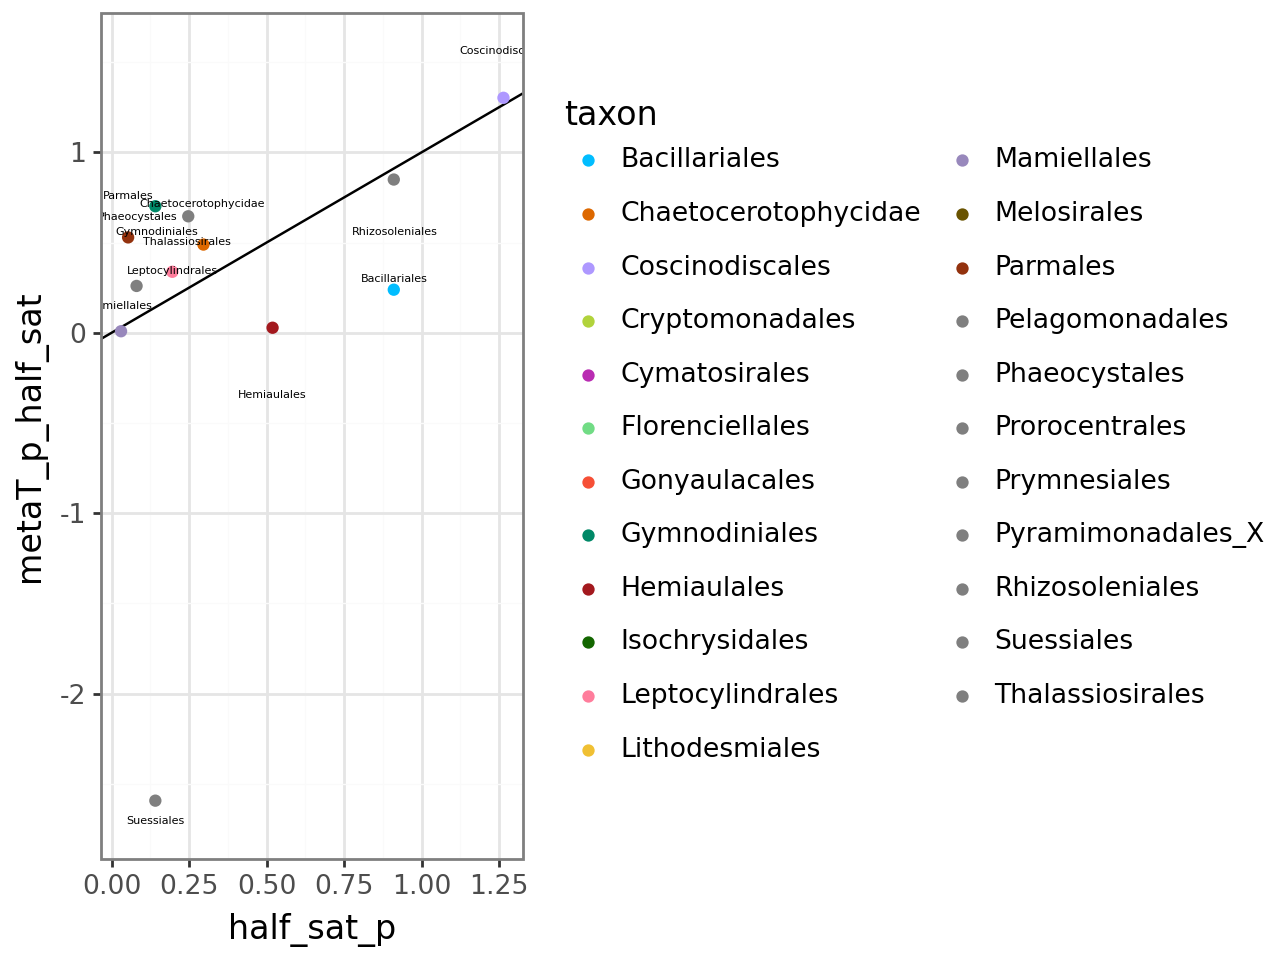

In [18]:
(plotnine.ggplot(merged_results)+
     plotnine.geom_abline(plotnine.aes(intercept=0,
                                       slope=1))+
     plotnine.geom_point(plotnine.aes(x="half_sat_p",
                                      y="metaT_p_half_sat",
                                      color="taxon"))+
     plotnine.geom_text(plotnine.aes(x="half_sat_p",
                                     y="metaT_p_half_sat",
                                     label="taxon"),
                        position="jitter",size=4) + 
     plotnine.theme_bw(base_size=12) +
     plotnine.scale_color_manual(values=["#01bdff",
"#dd6800",
"#ae98ff",
"#b1d33c",
"#b92cb2",
"#71dc85",
"#f64f36",
"#008867",
"#a3191e",
"#136600",
"#ff7d9c",
"#f0c033",
"#9888bc",
"#695300",
"#93320e"]))

/users/akrinos/miniconda3/envs/glm_new/lib/python3.13/site-packages/plotnine/scales/scale_manual.py:45: PlotnineWarning: The palette of scale_color_manual can return a maximum of 15 values. 23 were requested from it.
/users/akrinos/miniconda3/envs/glm_new/lib/python3.13/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_point : Removed 5 rows containing missing values.
/users/akrinos/miniconda3/envs/glm_new/lib/python3.13/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_text : Removed 5 rows containing missing values.
/users/akrinos/miniconda3/envs/glm_new/lib/python3.13/site-packages/plotnine/scales/scale_manual.py:45: PlotnineWarning: The palette of scale_color_manual can return a maximum of 15 values. 23 were requested from it.


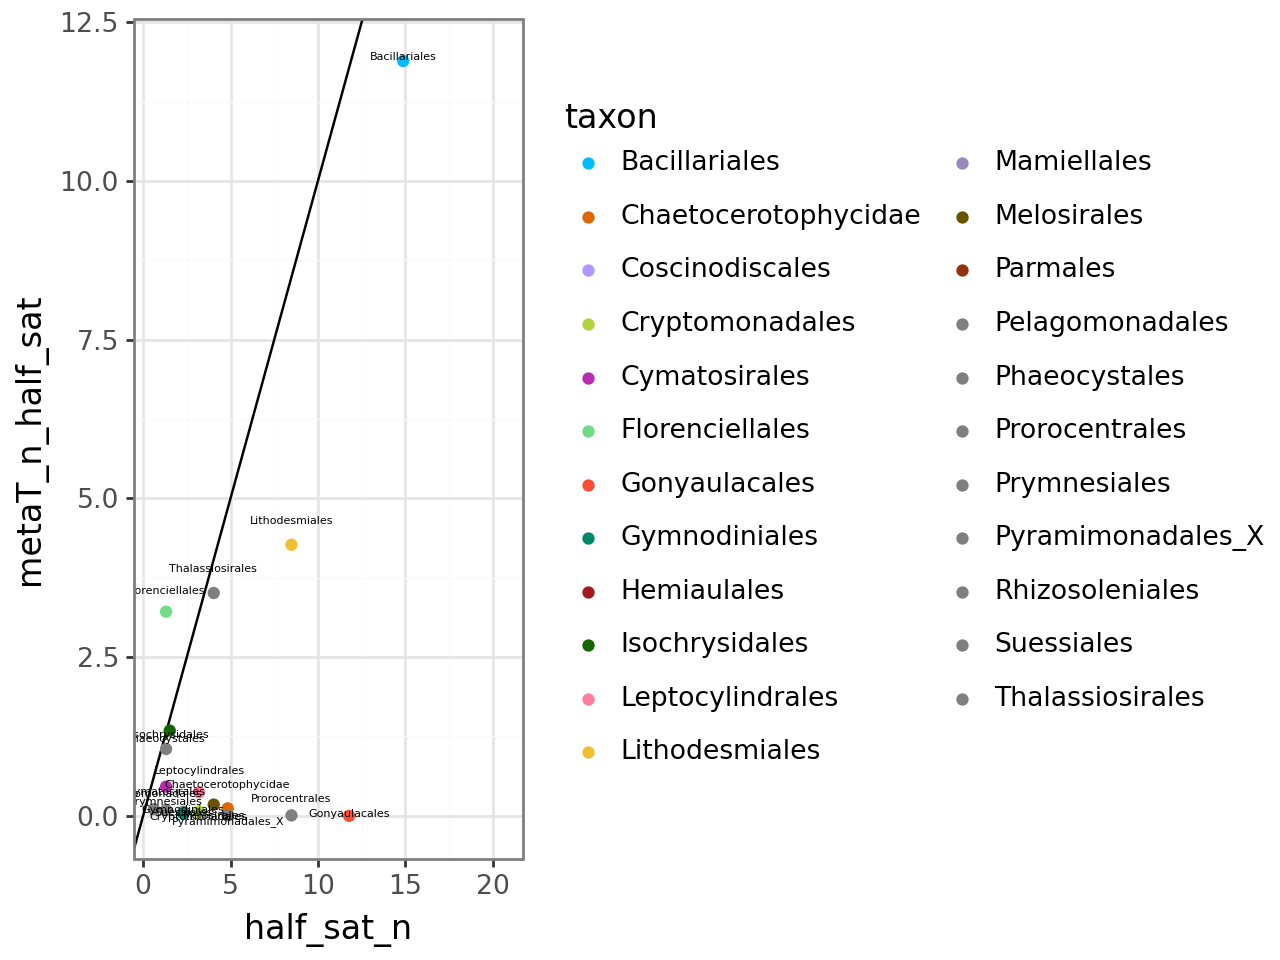

In [19]:
(plotnine.ggplot(merged_results)+
     plotnine.geom_abline(plotnine.aes(intercept=0,
                                       slope=1))+
     plotnine.geom_point(plotnine.aes(x="half_sat_n",
                                      y="metaT_n_half_sat",
                                      color="taxon"))+
     plotnine.geom_text(plotnine.aes(x="half_sat_n",
                                     y="metaT_n_half_sat",
                                     label="taxon"),
                        position="jitter",size=4) + 
     plotnine.theme_bw(base_size=12) +
     plotnine.scale_color_manual(values=["#01bdff",
"#dd6800",
"#ae98ff",
"#b1d33c",
"#b92cb2",
"#71dc85",
"#f64f36",
"#008867",
"#a3191e",
"#136600",
"#ff7d9c",
"#f0c033",
"#9888bc",
"#695300",
"#93320e"]))